In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

In [27]:
## Output folder for figures
out_dir = Path("output")
out_dir.mkdir(exist_ok=True)

### Data inspection and preprocessing

This notebook examines selective retention and spatial anchoring within the previous observation's KDE core. It reads the spatial measurements and randomisations exported by `compute_reuse_regularity.R` for diagnostic plots and statistical modelling.

`retention` describes previous territories and their subsequent persistence. `addition` compares spacing at the same reused current locations with and without newly observed core territories. `observed` and `randomisations` contain the corresponding transition summaries. Negative changes indicate reduced irregularity. Marking size is excluded as agreed.

In [28]:
## Load local measurements and persistence outcomes
local = pd.read_csv('processed_data/reuse_local_regularity.csv', parse_dates=['date'])
retention = pd.read_csv('processed_data/reuse_retention_pointwise.csv', parse_dates=['date_prev', 'date_curr'])
data = pd.read_csv('processed_data/reuse_transition_summary.csv', parse_dates=['date_prev', 'date_curr'])

In [29]:
## Load observed addition effects and their randomisations
addition = pd.read_csv('processed_data/reuse_addition_pointwise.csv', parse_dates=['date_prev', 'date_curr'])
observed = pd.read_csv('processed_data/reuse_addition_summary.csv', parse_dates=['date_prev', 'date_curr'])
randomisations = pd.read_csv('processed_data/reuse_addition_null.csv', parse_dates=['date_prev', 'date_curr'])

In [30]:
## Factor ordering + labels
lek_labels = ['Tal Chhapar', 'Velavadar Lek 1', 'Velavadar Lek 2']

for df in [local, retention, data, addition, observed, randomisations]:
    df['lek_id'] = pd.Categorical(df['lek_id'], categories=lek_labels, ordered=True)

In [31]:
## Colour palettes
fill_cols = {'Tal Chhapar': '#B5542D', 'Velavadar Lek 1': '#1F6F8B', 'Velavadar Lek 2': '#3FA7A3'}
point_cols = {'Tal Chhapar': '#D97A52', 'Velavadar Lek 1': '#15556B', 'Velavadar Lek 2': '#2B7E7B'}

lek_labels = data['lek_id'].cat.categories.tolist()

### Eligible focal locations across transitions

The counts below describe the reused current locations available for the addition comparison. NND and six-neighbour eligibility require the relevant neighbourhood to fit inside the lek polygon in both configurations. The CV is calculated across all six distances; the sixth distance supplies the radius for its boundary check.

The eligibility counts are shared by the observed and null comparisons. The transition without reused focal locations has no addition summary and receives zero eligible locations in this coverage table. Dates identify observation months, and spacing along the time axis reflects unequal observation intervals.

In [32]:
## Match comparison coverage to every observed transition
coverage = data.merge(observed[['lek_id', 'date_prev', 'date_curr', 'n_nnd_eligible', 'n_six_eligible']],
                      on=['lek_id', 'date_prev', 'date_curr'], how='left')
coverage[['n_nnd_eligible', 'n_six_eligible']] = coverage[['n_nnd_eligible', 'n_six_eligible']].fillna(0).astype(int)

In [33]:
coverage[['lek_id', 'date_prev', 'date_curr', 'n_reused', 'n_nnd_eligible', 'n_six_eligible', 'n_null_complete']]

,lek_id,date_prev,date_curr,n_reused,n_nnd_eligible,n_six_eligible,n_null_complete
0,Tal Chhapar,2012-10-01,2014-02-01,116,114,112,1000
1,Tal Chhapar,2014-02-01,2015-11-01,79,79,79,1000
2,Tal Chhapar,2015-11-01,2015-12-01,91,91,89,1000
3,Tal Chhapar,2015-12-01,2018-01-01,66,66,65,1000
4,Tal Chhapar,2018-01-01,2018-11-01,87,87,86,1000
5,Tal Chhapar,2018-11-01,2019-10-01,81,81,81,1000
6,Tal Chhapar,2019-10-01,2021-02-01,97,97,96,1000
7,Tal Chhapar,2021-02-01,2022-03-01,96,96,96,1000
8,Tal Chhapar,2022-03-01,2023-12-01,116,116,116,1000
9,Velavadar Lek 1,2013-12-01,2014-02-01,35,35,35,1000


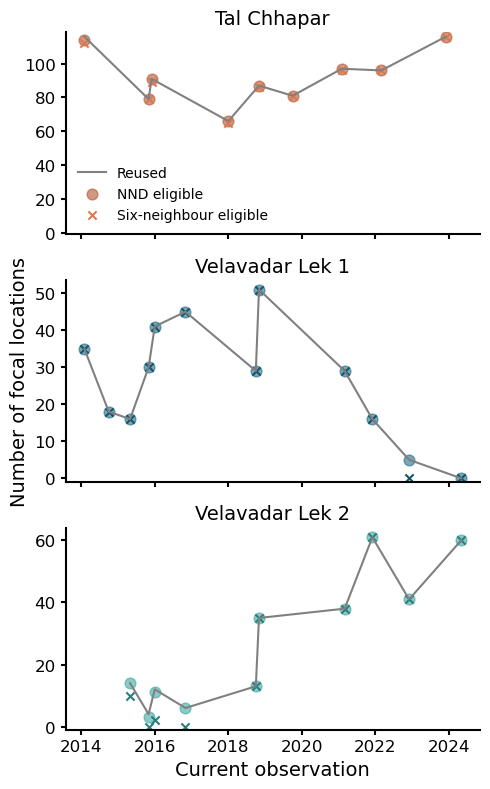

In [34]:
fig, axes = plt.subplots(3, 1, figsize=(5, 8), sharex=True)

for ax, lek in zip(axes, lek_labels):
    sub = coverage.loc[coverage['lek_id'] == lek].sort_values('date_curr')

    # Plot reused locations and the eligible neighbourhood counts
    ax.plot(sub['date_curr'], sub['n_reused'], color='grey', linewidth=1.5, label='Reused')
    ax.scatter(sub['date_curr'], sub['n_nnd_eligible'], s=60, color=fill_cols[lek], alpha=0.6, label='NND eligible')
    ax.scatter(sub['date_curr'], sub['n_six_eligible'], s=35, color=point_cols[lek], marker='x', linewidth=1.5, label='Six-neighbour eligible')
    ax.set_title(lek, fontsize=14)
    ax.set_ylim(bottom=-1)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)

axes[0].legend(frameon=False, fontsize=10)
axes[1].set_ylabel('Number of focal locations', fontsize=14)
axes[-1].set_xlabel('Current observation', fontsize=14)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()

### Selective retention: local spacing and subsequent persistence

These distributions compare the previous observation's local irregularity between locations that persist and those that do not persist into the next available observation. Persistence describes a nearby territorial location, rather than known individual male identity.

The sample includes previous territories inside their KDE core whose reuse-radius neighbourhood fits inside the lek polygon. Each spacing measure additionally uses its own boundary eligibility flag. The NND and CV panels can therefore have different sample sizes. Within each metric, all panels use the same bin edges; density scaling gives each persistence group equal area.

The distributions pool transitions within each lek. Legend counts are territory-observations. These are descriptive comparisons: observation date, interval, spatial dependence, and density still need consideration in the retention model.

In [35]:
## Define the local measures and the observed persistence sample
metrics = [('nnd_irregularity', 'nnd_edge_ok', 'NND irregularity'),
           ('six_neighbour_cv', 'six_neighbour_edge_ok', 'Six-neighbour distance CV')]
persistence_sample = retention.loc[retention['persistence_edge_ok']].copy()

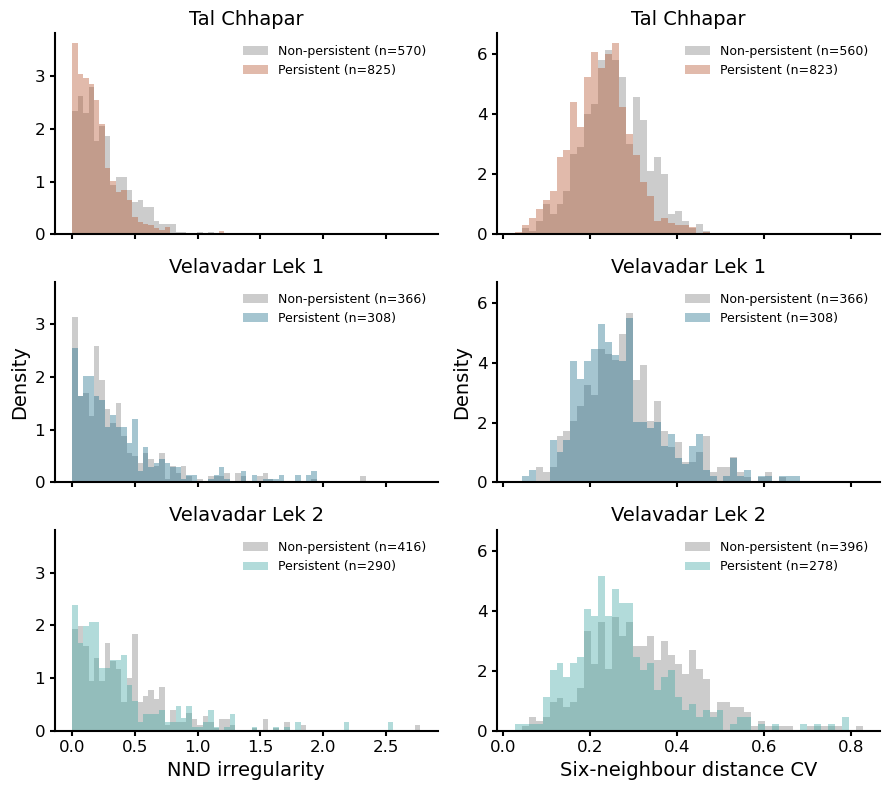

In [36]:
fig, axes = plt.subplots(3, 2, figsize=(9, 8), sharex='col', sharey='col')

for col, (metric, edge_flag, label) in enumerate(metrics):
    eligible = persistence_sample.loc[persistence_sample[edge_flag]]
    bins = np.histogram_bin_edges(eligible[metric], bins='fd')

    for row, lek in enumerate(lek_labels):
        ax = axes[row, col]
        sub = eligible.loc[eligible['lek_id'] == lek]
        obs = sub.loc[sub['persistent'], metric].to_numpy()
        nonpersistent = sub.loc[~sub['persistent'], metric].to_numpy()

        # Compare persistence groups using common bins and density scaling
        ax.hist(nonpersistent, bins=bins, density=True, color='grey', alpha=0.4,
                label=f'Non-persistent (n={len(nonpersistent)})')
        ax.hist(obs, bins=bins, density=True, color=fill_cols[lek], alpha=0.4,
                label=f'Persistent (n={len(obs)})')
        ax.set_title(lek, fontsize=14)
        ax.legend(frameon=False, fontsize=9)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)

    axes[-1, col].set_xlabel(label, fontsize=14)
    axes[1, col].set_ylabel('Density', fontsize=14)

plt.tight_layout()
plt.show()

### Selective retention: transition-adjusted logistic models

The reuse model in `model_territory_sizes.ipynb` supplies the Bernoulli-logit likelihood, priors, and sampling settings. Each local measure is fitted separately, with an intercept for every lek-transition and a separate irregularity slope for each lek.

Irregularity is centred at its transition-specific mean, then divided by the overall standard deviation of that measure in the eligible sample. A slope therefore describes a one-standard-deviation increase relative to contemporaries. Negative slopes support preferential persistence of more regularly positioned territories.

The model reuses `normal(0, 1)` priors for both intercepts and slopes. Each intercept refers to the average eligible territory in its own transition. Transition baselines absorb shared differences between observation pairs, including their overall persistence rates. The model treats territory outcomes as conditionally independent; local density and residual spatial dependence remain limitations of this initial association analysis.

In [37]:
import stan
import arviz as az

import nest_asyncio
nest_asyncio.apply()

ModuleNotFoundError: No module named 'stan'

In [ ]:
## Prepare the eligible samples and centre irregularity within transitions
retention_tables = {}

for metric, edge_flag, label in metrics:
    sample = persistence_sample.loc[persistence_sample[edge_flag]].copy().reset_index(drop=True)
    sample['site_id'] = sample['lek_id'].cat.codes
    sample['transition_id'] = sample.groupby(['lek_id', 'date_prev', 'date_curr'], observed=True).ngroup()
    irregularity_centred = sample[metric] - sample.groupby('transition_id')[metric].transform('mean')
    sample['irregularity_z'] = np.array(irregularity_centred / sample[metric].std())
    retention_tables[metric] = sample

Python site and transition IDs start at zero. The Stan program converts them to its required internal array indices. `reuse_rep` stores posterior-predictive persistence counts for each transition.

In [ ]:
## Model persistence using transition baselines and lek-specific irregularity effects
reuse_mod = """
data {
    int<lower=1> n_points;
    int<lower=1> n_transitions;
    int<lower=1> n_sites;
    array[n_points] int<lower=0, upper=1> reuse;
    array[n_points] int<lower=0, upper=n_transitions-1> transition_id;
    array[n_points] int<lower=0, upper=n_sites-1> site_id;
    vector[n_points] irregularity;
}

transformed data {
    array[n_points] int transition_index;
    array[n_points] int site_index;

    for (n in 0:(n_points - 1)) {
        int idx = n + 1;
        transition_index[idx] = transition_id[idx] + 1;
        site_index[idx] = site_id[idx] + 1;
    }
}

parameters {
    vector[n_transitions] alpha;
    vector[n_sites] beta;
}

model {
    alpha ~ normal(0, 1);
    beta  ~ normal(0, 1);

    reuse ~ bernoulli_logit(alpha[transition_index] + beta[site_index] .* irregularity);
}

generated quantities {
    array[n_transitions] int<lower=0> reuse_rep = rep_array(0, n_transitions);

    for (n in 0:(n_points - 1)) {
        int idx = n + 1;
        reuse_rep[transition_index[idx]] += bernoulli_logit_rng(alpha[transition_index[idx]]
                                          + beta[site_index[idx]] * irregularity[idx]);
    }
}
"""

In [ ]:
## Fit each local measure with the reuse model's sampling settings
retention_posteriors = {}
retention_fits = {}

for metric, edge_flag, label in metrics:
    sample = retention_tables[metric]
    reuse_data = {
        'n_points': len(sample),
        'n_transitions': int(sample['transition_id'].nunique()),
        'n_sites': len(lek_labels),
        'reuse': sample['persistent'].astype(int).to_numpy(),
        'transition_id': sample['transition_id'].astype(int).to_numpy(),
        'site_id': sample['site_id'].astype(int).to_numpy(),
        'irregularity': sample['irregularity_z'].astype(float).to_numpy()
    }

    posterior = stan.build(reuse_mod, data=reuse_data, random_seed=123)
    retention_posteriors[metric] = posterior
    retention_fits[metric] = posterior.sample(num_chains=4, num_warmup=1000, num_samples=1000)

### Retention model diagnostics and effects

Chain agreement, effective sample sizes, and divergent transitions are checked before interpreting slopes. Posterior-predictive persistence counts provide a basic check of transition-level fit; they do not assess residual spatial dependence.

The effect table and violin plots summarise the posterior slopes. A negative coefficient, or an odds ratio below one, corresponds to lower persistence odds with greater irregularity. `Pr(beta < 0)` is a posterior probability under this model. The intervals are central posterior intervals, and the two spacing measures retain their own eligible samples.

In [ ]:
## Summarise chain mixing and sampler diagnostics
retention_idata = {}
diagnostic_rows = []

for metric, edge_flag, label in metrics:
    sample = retention_tables[metric]
    idata = az.from_pystan(posterior=retention_fits[metric], posterior_model=retention_posteriors[metric],
                          posterior_predictive=['reuse_rep'], observed_data=['reuse'],
                          coords={'lek': lek_labels, 'transition': np.arange(sample['transition_id'].nunique())},
                          dims={'beta': ['lek'], 'alpha': ['transition'], 'reuse_rep': ['transition']})
    retention_idata[metric] = idata
    diagnostics = az.summary(idata, var_names=['alpha', 'beta'], kind='diagnostics', round_to=3)
    diagnostic_rows.append({'measure': label, 'max_rhat': diagnostics['r_hat'].max(),
                            'min_bulk_ess': diagnostics['ess_bulk'].min(), 'min_tail_ess': diagnostics['ess_tail'].min(),
                            'divergences': int(idata.sample_stats['diverging'].sum()),
                            'max_tree_depth': int(idata.sample_stats['tree_depth'].max()), 'min_bfmi': az.bfmi(idata).min()})

pd.DataFrame(diagnostic_rows)

In [ ]:
## Compare observed transition rates with posterior-predictive persistence rates
predictive_rows = []

for metric, edge_flag, label in metrics:
    sample = retention_tables[metric]
    counts = sample.groupby('transition_id')['persistent'].agg(['size', 'mean'])
    p_rep = retention_fits[metric]['reuse_rep'] / counts['size'].to_numpy()[:, None]
    p_lower, p_upper = np.quantile(p_rep, [0.025, 0.975], axis=1)
    outside = (counts['mean'].to_numpy() < p_lower) | (counts['mean'].to_numpy() > p_upper)
    predictive_rows.append({'measure': label, 'n_transitions': len(counts),
                            'outside_predictive_interval': int(outside.sum()),
                            'mean_absolute_rate_error': np.mean(np.abs(counts['mean'].to_numpy() - p_rep.mean(axis=1)))})

pd.DataFrame(predictive_rows)

In [ ]:
## Summarise irregularity effects and their posterior uncertainty
retention_effect_rows = []

for metric, edge_flag, label in metrics:
    for site_id, lek in enumerate(lek_labels):
        samples = retention_fits[metric]['beta'][site_id, :]
        lower, median, upper = np.quantile(samples, [0.025, 0.5, 0.975])
        retention_effect_rows.append({'measure': label, 'lek_id': lek, 'beta_median': median,
                                      'beta_lower': lower, 'beta_upper': upper, 'odds_ratio': np.exp(median),
                                      'odds_ratio_lower': np.exp(lower), 'odds_ratio_upper': np.exp(upper),
                                      'Pr(beta < 0)': np.mean(samples < 0)})

retention_effects = pd.DataFrame(retention_effect_rows)
retention_effects

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
x_pos = np.arange(len(lek_labels))

for ax, (metric, edge_flag, label) in zip(axes, metrics):
    for site_id, lek in enumerate(lek_labels):
        samples = retention_fits[metric]['beta'][site_id, :]

        # Plot the posterior irregularity effect for each lek
        parts = ax.violinplot(samples, positions=[x_pos[site_id]], widths=0.6,
                              showmeans=False, showmedians=False, showextrema=False)
        for pc in parts['bodies']:
            pc.set_facecolor(fill_cols.get(lek))
            pc.set_edgecolor('none')
            pc.set_alpha(0.4)

        median = np.median(samples)
        lower, upper = np.quantile(samples, [0.025, 0.975])
        ax.errorbar(x_pos[site_id], median, yerr=[[median-lower], [upper-median]],
                    fmt='o', color=fill_cols.get(lek), markersize=6, capsize=2, zorder=3)

    ax.axhline(0, linestyle='--', color='black', linewidth=1)
    ax.set_xlim(-0.5, len(lek_labels) - 0.5)
    ax.set_title(label, fontsize=14)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(lek_labels, fontsize=10, rotation=15, ha='right')

axes[0].set_ylabel('Persistence effect\n(log odds per SD)', fontsize=14)
plt.tight_layout()
plt.show()

### Spatial anchoring: observed additions versus random placement

For each transition, the observed addition effect is the mean change in local irregularity at reused current locations when newly observed core territories are added. Negative change means reduced irregularity. The current observation's reference NND and the outside-core neighbours remain fixed.

The null preserves the number of additions, reused locations, outside-core neighbours, and eligible focal locations. New positions follow the previous KDE inside its core and remain beyond the reuse threshold from every previous territory. The null imposes no further spacing constraint, so an observed advantage can also reflect general territorial spacing.

Grey points show the median simulated mean change, and their error bars span the central 95% of simulations. Coloured points below the grey median have a larger reduction, or a smaller increase, in irregularity than the typical null configuration. The dashed zero line marks no observed change in spacing. Missing CV comparisons appear as gaps. These panels compare each transition with its own null distribution and use the mean as an initial diagnostic summary.

In [ ]:
## Define the addition statistics and their transition keys
addition_metrics = [('mean_delta_nnd_irregularity', 'Mean change in\nNND irregularity'),
                    ('mean_delta_six_neighbour_cv', 'Mean change in\nsix-neighbour CV')]
comparison_keys = ['lek_id', 'date_prev', 'date_curr']

In [ ]:
## Match observed changes to their transition-specific null envelopes
addition_comparisons = {}

for metric, label in addition_metrics:
    null_summary = (randomisations.loc[randomisations['complete']].groupby(comparison_keys, observed=True)[metric]
                    .quantile([0.025, 0.5, 0.975]).unstack()
                    .rename(columns={0.025: 'null_lower', 0.5: 'null_median', 0.975: 'null_upper'}).reset_index())
    addition_comparisons[metric] = observed.merge(null_summary, on=comparison_keys, how='left')

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(9, 8), sharex=True, sharey='col')

for col, (metric, label) in enumerate(addition_metrics):
    comparison = addition_comparisons[metric]

    for row, lek in enumerate(lek_labels):
        ax = axes[row, col]
        sub = comparison.loc[comparison['lek_id'] == lek].sort_values('date_curr')

        # Plot the null intervals and the observed mean change
        ax.errorbar(sub['date_curr'], sub['null_median'],
                    yerr=[sub['null_median'] - sub['null_lower'], sub['null_upper'] - sub['null_median']],
                    fmt='o', markersize=5, color='grey', capsize=2, zorder=3, label='Null median and central 95%')
        ax.scatter(sub['date_curr'], sub[metric], s=80, color=point_cols.get(lek),
                   edgecolor=fill_cols.get(lek), alpha=0.8, zorder=4, label='Observed')
        ax.axhline(0, color='#444444', linewidth=1, linestyle='dashed')
        ax.set_title(lek, fontsize=14)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)

    axes[0, col].legend(frameon=False, fontsize=9)
    axes[1, col].set_ylabel(label, fontsize=14)
    axes[-1, col].set_xlabel('Current observation', fontsize=14)
    axes[-1, col].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1, col].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()